# Aula 1 — Machine Learning para Sistemas de Engenharia
## Do dado ao surrogate model: previsão de resistência de casco com MLP e RBF em PyTorch/SciPy

**Disciplina:** Otimização — IA aplicada à Engenharia Naval e Oceânica
**Exemplo:** Yacht Hydrodynamics Dataset (Delft Ship Hydromechanics Laboratory, via UCI ML Repository)

Fluxo da aula:

`dado de engenharia → Machine Learning → predição rápida → projeto/otimização`

Este notebook treina dois surrogates diferentes sobre os mesmos dados — uma **MLP** (PyTorch) e um
**interpolador RBF** (SciPy) — e usa ambos para otimizar a geometria do casco, restringindo a busca a
combinações convexas dos 22 cascos reais (evitando extrapolar para fora do domínio de treino). Roda em
CPU em poucos segundos.


## 1. Imports

In [1]:
import io
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import requests
import scipy.optimize as opt
from scipy.interpolate import RBFInterpolator
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")  # deixa a saída mais limpa em aula
torch.manual_seed(0)
np.random.seed(0)

DEVICE = "cpu"  # notebook pensado para rodar sem GPU
print("PyTorch:", torch.__version__, "| device:", DEVICE)


PyTorch: 2.14.0+cu130 | device: cpu


## 2. Carregar o dataset (Yacht Hydrodynamics — UCI)

Seguindo o padrão do repositório do curso: o pacote `ucimlrepo` não tem suporte padronizado para este
dataset, então baixamos direto do `.zip` oficial que a UCI disponibiliza.

Para garantir que a aula não dependa de internet no dia (rede da sala, firewall, link fora do ar), a célula
abaixo tenta, em ordem: **(1)** o download oficial, **(2)** um CSV local na mesma pasta do notebook, **(3)**
uma cópia embutida com os mesmos dados. O resultado final é idêntico nos três casos.


In [2]:
DATA_URL = "https://archive.ics.uci.edu/static/public/243/yacht+hydrodynamics.zip"
LOCAL_CSV = "data/yacht_hydrodynamics.csv"
col_names = ["LCB", "Cp", "L_disp", "B_T", "L_B", "Froude", "Rr"]

_EMBEDDED_CSV = """LCB,Cp,L_disp,B_T,L_B,Froude,Rr
-2.3,0.568,4.78,3.99,3.17,0.125,0.11
-2.3,0.568,4.78,3.99,3.17,0.15,0.27
-2.3,0.568,4.78,3.99,3.17,0.175,0.47
-2.3,0.568,4.78,3.99,3.17,0.2,0.78
-2.3,0.568,4.78,3.99,3.17,0.225,1.18
-2.3,0.568,4.78,3.99,3.17,0.25,1.82
-2.3,0.568,4.78,3.99,3.17,0.275,2.61
-2.3,0.568,4.78,3.99,3.17,0.3,3.76
-2.3,0.568,4.78,3.99,3.17,0.325,4.99
-2.3,0.568,4.78,3.99,3.17,0.35,7.16
-2.3,0.568,4.78,3.99,3.17,0.375,11.93
-2.3,0.568,4.78,3.99,3.17,0.4,20.11
-2.3,0.568,4.78,3.99,3.17,0.425,32.75
-2.3,0.568,4.78,3.99,3.17,0.45,49.49
-2.3,0.569,4.78,3.04,3.64,0.125,0.04
-2.3,0.569,4.78,3.04,3.64,0.15,0.17
-2.3,0.569,4.78,3.04,3.64,0.175,0.37
-2.3,0.569,4.78,3.04,3.64,0.2,0.66
-2.3,0.569,4.78,3.04,3.64,0.225,1.06
-2.3,0.569,4.78,3.04,3.64,0.25,1.59
-2.3,0.569,4.78,3.04,3.64,0.275,2.33
-2.3,0.569,4.78,3.04,3.64,0.3,3.29
-2.3,0.569,4.78,3.04,3.64,0.325,4.61
-2.3,0.569,4.78,3.04,3.64,0.35,7.11
-2.3,0.569,4.78,3.04,3.64,0.375,11.99
-2.3,0.569,4.78,3.04,3.64,0.4,21.09
-2.3,0.569,4.78,3.04,3.64,0.425,35.01
-2.3,0.569,4.78,3.04,3.64,0.45,51.8
-2.3,0.565,4.78,5.35,2.76,0.125,0.09
-2.3,0.565,4.78,5.35,2.76,0.15,0.29
-2.3,0.565,4.78,5.35,2.76,0.175,0.56
-2.3,0.565,4.78,5.35,2.76,0.2,0.86
-2.3,0.565,4.78,5.35,2.76,0.225,1.31
-2.3,0.565,4.78,5.35,2.76,0.25,1.99
-2.3,0.565,4.78,5.35,2.76,0.275,2.94
-2.3,0.565,4.78,5.35,2.76,0.3,4.21
-2.3,0.565,4.78,5.35,2.76,0.325,5.54
-2.3,0.565,4.78,5.35,2.76,0.35,8.25
-2.3,0.565,4.78,5.35,2.76,0.375,13.08
-2.3,0.565,4.78,5.35,2.76,0.4,21.4
-2.3,0.565,4.78,5.35,2.76,0.425,33.14
-2.3,0.565,4.78,5.35,2.76,0.45,50.14
-2.3,0.564,5.1,3.95,3.53,0.125,0.2
-2.3,0.564,5.1,3.95,3.53,0.15,0.35
-2.3,0.564,5.1,3.95,3.53,0.175,0.65
-2.3,0.564,5.1,3.95,3.53,0.2,0.93
-2.3,0.564,5.1,3.95,3.53,0.225,1.37
-2.3,0.564,5.1,3.95,3.53,0.25,1.97
-2.3,0.564,5.1,3.95,3.53,0.275,2.83
-2.3,0.564,5.1,3.95,3.53,0.3,3.99
-2.3,0.564,5.1,3.95,3.53,0.325,5.19
-2.3,0.564,5.1,3.95,3.53,0.35,8.03
-2.3,0.564,5.1,3.95,3.53,0.375,12.86
-2.3,0.564,5.1,3.95,3.53,0.4,21.51
-2.3,0.564,5.1,3.95,3.53,0.425,33.97
-2.3,0.564,5.1,3.95,3.53,0.45,50.36
-2.4,0.574,4.36,3.96,2.76,0.125,0.2
-2.4,0.574,4.36,3.96,2.76,0.15,0.35
-2.4,0.574,4.36,3.96,2.76,0.175,0.65
-2.4,0.574,4.36,3.96,2.76,0.2,0.93
-2.4,0.574,4.36,3.96,2.76,0.225,1.37
-2.4,0.574,4.36,3.96,2.76,0.25,1.97
-2.4,0.574,4.36,3.96,2.76,0.275,2.83
-2.4,0.574,4.36,3.96,2.76,0.3,3.99
-2.4,0.574,4.36,3.96,2.76,0.325,5.19
-2.4,0.574,4.36,3.96,2.76,0.35,8.03
-2.4,0.574,4.36,3.96,2.76,0.375,12.86
-2.4,0.574,4.36,3.96,2.76,0.4,21.51
-2.4,0.574,4.36,3.96,2.76,0.425,33.97
-2.4,0.574,4.36,3.96,2.76,0.45,50.36
-2.4,0.568,4.34,2.98,3.15,0.125,0.12
-2.4,0.568,4.34,2.98,3.15,0.15,0.26
-2.4,0.568,4.34,2.98,3.15,0.175,0.43
-2.4,0.568,4.34,2.98,3.15,0.2,0.69
-2.4,0.568,4.34,2.98,3.15,0.225,1.09
-2.4,0.568,4.34,2.98,3.15,0.25,1.67
-2.4,0.568,4.34,2.98,3.15,0.275,2.46
-2.4,0.568,4.34,2.98,3.15,0.3,3.43
-2.4,0.568,4.34,2.98,3.15,0.325,4.62
-2.4,0.568,4.34,2.98,3.15,0.35,6.86
-2.4,0.568,4.34,2.98,3.15,0.375,11.56
-2.4,0.568,4.34,2.98,3.15,0.4,20.63
-2.4,0.568,4.34,2.98,3.15,0.425,34.5
-2.4,0.568,4.34,2.98,3.15,0.45,54.23
-2.3,0.562,5.14,4.95,3.17,0.125,0.28
-2.3,0.562,5.14,4.95,3.17,0.15,0.44
-2.3,0.562,5.14,4.95,3.17,0.175,0.7
-2.3,0.562,5.14,4.95,3.17,0.2,1.07
-2.3,0.562,5.14,4.95,3.17,0.225,1.57
-2.3,0.562,5.14,4.95,3.17,0.25,2.23
-2.3,0.562,5.14,4.95,3.17,0.275,3.09
-2.3,0.562,5.14,4.95,3.17,0.3,4.09
-2.3,0.562,5.14,4.95,3.17,0.325,5.82
-2.3,0.562,5.14,4.95,3.17,0.35,8.28
-2.3,0.562,5.14,4.95,3.17,0.375,12.8
-2.3,0.562,5.14,4.95,3.17,0.4,20.41
-2.3,0.562,5.14,4.95,3.17,0.425,32.34
-2.3,0.562,5.14,4.95,3.17,0.45,47.29
-2.4,0.585,4.78,3.84,3.32,0.125,0.2
-2.4,0.585,4.78,3.84,3.32,0.15,0.38
-2.4,0.585,4.78,3.84,3.32,0.175,0.64
-2.4,0.585,4.78,3.84,3.32,0.2,0.97
-2.4,0.585,4.78,3.84,3.32,0.225,1.36
-2.4,0.585,4.78,3.84,3.32,0.25,1.98
-2.4,0.585,4.78,3.84,3.32,0.275,2.91
-2.4,0.585,4.78,3.84,3.32,0.3,4.35
-2.4,0.585,4.78,3.84,3.32,0.325,5.79
-2.4,0.585,4.78,3.84,3.32,0.35,8.04
-2.4,0.585,4.78,3.84,3.32,0.375,12.15
-2.4,0.585,4.78,3.84,3.32,0.4,19.18
-2.4,0.585,4.78,3.84,3.32,0.425,30.09
-2.4,0.585,4.78,3.84,3.32,0.45,44.38
-2.2,0.546,4.78,4.13,3.07,0.125,0.15
-2.2,0.546,4.78,4.13,3.07,0.15,0.32
-2.2,0.546,4.78,4.13,3.07,0.175,0.55
-2.2,0.546,4.78,4.13,3.07,0.2,0.86
-2.2,0.546,4.78,4.13,3.07,0.225,1.24
-2.2,0.546,4.78,4.13,3.07,0.25,1.76
-2.2,0.546,4.78,4.13,3.07,0.275,2.49
-2.2,0.546,4.78,4.13,3.07,0.3,3.45
-2.2,0.546,4.78,4.13,3.07,0.325,4.83
-2.2,0.546,4.78,4.13,3.07,0.35,7.37
-2.2,0.546,4.78,4.13,3.07,0.375,12.76
-2.2,0.546,4.78,4.13,3.07,0.4,21.99
-2.2,0.546,4.78,4.13,3.07,0.425,35.64
-2.2,0.546,4.78,4.13,3.07,0.45,53.07
0.0,0.565,4.77,3.99,3.15,0.125,0.11
0.0,0.565,4.77,3.99,3.15,0.15,0.24
0.0,0.565,4.77,3.99,3.15,0.175,0.49
0.0,0.565,4.77,3.99,3.15,0.2,0.79
0.0,0.565,4.77,3.99,3.15,0.225,1.28
0.0,0.565,4.77,3.99,3.15,0.25,1.96
0.0,0.565,4.77,3.99,3.15,0.275,2.88
0.0,0.565,4.77,3.99,3.15,0.3,4.14
0.0,0.565,4.77,3.99,3.15,0.325,5.96
0.0,0.565,4.77,3.99,3.15,0.35,9.07
0.0,0.565,4.77,3.99,3.15,0.375,14.93
0.0,0.565,4.77,3.99,3.15,0.4,24.13
0.0,0.565,4.77,3.99,3.15,0.425,38.12
0.0,0.565,4.77,3.99,3.15,0.45,55.44
-5.0,0.565,4.77,3.99,3.15,0.125,0.07
-5.0,0.565,4.77,3.99,3.15,0.15,0.18
-5.0,0.565,4.77,3.99,3.15,0.175,0.4
-5.0,0.565,4.77,3.99,3.15,0.2,0.7
-5.0,0.565,4.77,3.99,3.15,0.225,1.14
-5.0,0.565,4.77,3.99,3.15,0.25,1.83
-5.0,0.565,4.77,3.99,3.15,0.275,2.77
-5.0,0.565,4.77,3.99,3.15,0.3,4.12
-5.0,0.565,4.77,3.99,3.15,0.325,5.41
-5.0,0.565,4.77,3.99,3.15,0.35,7.87
-5.0,0.565,4.77,3.99,3.15,0.375,12.71
-5.0,0.565,4.77,3.99,3.15,0.4,21.02
-5.0,0.565,4.77,3.99,3.15,0.425,34.58
-5.0,0.565,4.77,3.99,3.15,0.45,51.77
0.0,0.565,5.1,3.94,3.51,0.125,0.08
0.0,0.565,5.1,3.94,3.51,0.15,0.26
0.0,0.565,5.1,3.94,3.51,0.175,0.5
0.0,0.565,5.1,3.94,3.51,0.2,0.83
0.0,0.565,5.1,3.94,3.51,0.225,1.28
0.0,0.565,5.1,3.94,3.51,0.25,1.9
0.0,0.565,5.1,3.94,3.51,0.275,2.68
0.0,0.565,5.1,3.94,3.51,0.3,3.76
0.0,0.565,5.1,3.94,3.51,0.325,5.57
0.0,0.565,5.1,3.94,3.51,0.35,8.76
0.0,0.565,5.1,3.94,3.51,0.375,14.24
0.0,0.565,5.1,3.94,3.51,0.4,23.05
0.0,0.565,5.1,3.94,3.51,0.425,35.46
0.0,0.565,5.1,3.94,3.51,0.45,51.99
-5.0,0.565,5.1,3.94,3.51,0.125,0.08
-5.0,0.565,5.1,3.94,3.51,0.15,0.24
-5.0,0.565,5.1,3.94,3.51,0.175,0.45
-5.0,0.565,5.1,3.94,3.51,0.2,0.77
-5.0,0.565,5.1,3.94,3.51,0.225,1.19
-5.0,0.565,5.1,3.94,3.51,0.25,1.76
-5.0,0.565,5.1,3.94,3.51,0.275,2.59
-5.0,0.565,5.1,3.94,3.51,0.3,3.85
-5.0,0.565,5.1,3.94,3.51,0.325,5.27
-5.0,0.565,5.1,3.94,3.51,0.35,7.74
-5.0,0.565,5.1,3.94,3.51,0.375,12.4
-5.0,0.565,5.1,3.94,3.51,0.4,20.91
-5.0,0.565,5.1,3.94,3.51,0.425,33.23
-5.0,0.565,5.1,3.94,3.51,0.45,49.14
-2.3,0.53,5.11,3.69,3.51,0.125,0.08
-2.3,0.53,5.11,3.69,3.51,0.15,0.25
-2.3,0.53,5.11,3.69,3.51,0.175,0.46
-2.3,0.53,5.11,3.69,3.51,0.2,0.75
-2.3,0.53,5.11,3.69,3.51,0.225,1.11
-2.3,0.53,5.11,3.69,3.51,0.25,1.57
-2.3,0.53,5.11,3.69,3.51,0.275,2.17
-2.3,0.53,5.11,3.69,3.51,0.3,2.98
-2.3,0.53,5.11,3.69,3.51,0.325,4.42
-2.3,0.53,5.11,3.69,3.51,0.35,7.84
-2.3,0.53,5.11,3.69,3.51,0.375,14.11
-2.3,0.53,5.11,3.69,3.51,0.4,24.14
-2.3,0.53,5.11,3.69,3.51,0.425,37.95
-2.3,0.53,5.11,3.69,3.51,0.45,55.17
-2.3,0.53,4.76,3.68,3.16,0.125,0.1
-2.3,0.53,4.76,3.68,3.16,0.15,0.23
-2.3,0.53,4.76,3.68,3.16,0.175,0.47
-2.3,0.53,4.76,3.68,3.16,0.2,0.76
-2.3,0.53,4.76,3.68,3.16,0.225,1.15
-2.3,0.53,4.76,3.68,3.16,0.25,1.65
-2.3,0.53,4.76,3.68,3.16,0.275,2.28
-2.3,0.53,4.76,3.68,3.16,0.3,3.09
-2.3,0.53,4.76,3.68,3.16,0.325,4.41
-2.3,0.53,4.76,3.68,3.16,0.35,7.51
-2.3,0.53,4.76,3.68,3.16,0.375,13.77
-2.3,0.53,4.76,3.68,3.16,0.4,23.96
-2.3,0.53,4.76,3.68,3.16,0.425,37.38
-2.3,0.53,4.76,3.68,3.16,0.45,56.46
-2.3,0.53,4.34,2.81,3.15,0.125,0.05
-2.3,0.53,4.34,2.81,3.15,0.15,0.17
-2.3,0.53,4.34,2.81,3.15,0.175,0.35
-2.3,0.53,4.34,2.81,3.15,0.2,0.63
-2.3,0.53,4.34,2.81,3.15,0.225,1.01
-2.3,0.53,4.34,2.81,3.15,0.25,1.43
-2.3,0.53,4.34,2.81,3.15,0.275,2.05
-2.3,0.53,4.34,2.81,3.15,0.3,2.73
-2.3,0.53,4.34,2.81,3.15,0.325,3.87
-2.3,0.53,4.34,2.81,3.15,0.35,7.19
-2.3,0.53,4.34,2.81,3.15,0.375,13.96
-2.3,0.53,4.34,2.81,3.15,0.4,25.18
-2.3,0.53,4.34,2.81,3.15,0.425,41.34
-2.3,0.53,4.34,2.81,3.15,0.45,62.42
0.0,0.6,4.78,4.24,3.15,0.125,0.03
0.0,0.6,4.78,4.24,3.15,0.15,0.18
0.0,0.6,4.78,4.24,3.15,0.175,0.4
0.0,0.6,4.78,4.24,3.15,0.2,0.73
0.0,0.6,4.78,4.24,3.15,0.225,1.3
0.0,0.6,4.78,4.24,3.15,0.25,2.16
0.0,0.6,4.78,4.24,3.15,0.275,3.35
0.0,0.6,4.78,4.24,3.15,0.3,5.06
0.0,0.6,4.78,4.24,3.15,0.325,7.14
0.0,0.6,4.78,4.24,3.15,0.35,10.36
0.0,0.6,4.78,4.24,3.15,0.375,15.25
0.0,0.6,4.78,4.24,3.15,0.4,23.15
0.0,0.6,4.78,4.24,3.15,0.425,34.62
0.0,0.6,4.78,4.24,3.15,0.45,51.5
-5.0,0.6,4.78,4.24,3.15,0.125,0.06
-5.0,0.6,4.78,4.24,3.15,0.15,0.15
-5.0,0.6,4.78,4.24,3.15,0.175,0.34
-5.0,0.6,4.78,4.24,3.15,0.2,0.63
-5.0,0.6,4.78,4.24,3.15,0.225,1.13
-5.0,0.6,4.78,4.24,3.15,0.25,1.85
-5.0,0.6,4.78,4.24,3.15,0.275,2.84
-5.0,0.6,4.78,4.24,3.15,0.3,4.34
-5.0,0.6,4.78,4.24,3.15,0.325,6.2
-5.0,0.6,4.78,4.24,3.15,0.35,8.62
-5.0,0.6,4.78,4.24,3.15,0.375,12.49
-5.0,0.6,4.78,4.24,3.15,0.4,20.41
-5.0,0.6,4.78,4.24,3.15,0.425,32.46
-5.0,0.6,4.78,4.24,3.15,0.45,50.94
0.0,0.53,4.78,3.75,3.15,0.125,0.16
0.0,0.53,4.78,3.75,3.15,0.15,0.32
0.0,0.53,4.78,3.75,3.15,0.175,0.59
0.0,0.53,4.78,3.75,3.15,0.2,0.92
0.0,0.53,4.78,3.75,3.15,0.225,1.37
0.0,0.53,4.78,3.75,3.15,0.25,1.94
0.0,0.53,4.78,3.75,3.15,0.275,2.62
0.0,0.53,4.78,3.75,3.15,0.3,3.7
0.0,0.53,4.78,3.75,3.15,0.325,5.45
0.0,0.53,4.78,3.75,3.15,0.35,9.45
0.0,0.53,4.78,3.75,3.15,0.375,16.31
0.0,0.53,4.78,3.75,3.15,0.4,27.34
0.0,0.53,4.78,3.75,3.15,0.425,41.77
0.0,0.53,4.78,3.75,3.15,0.45,60.85
-5.0,0.53,4.78,3.75,3.15,0.125,0.09
-5.0,0.53,4.78,3.75,3.15,0.15,0.24
-5.0,0.53,4.78,3.75,3.15,0.175,0.47
-5.0,0.53,4.78,3.75,3.15,0.2,0.78
-5.0,0.53,4.78,3.75,3.15,0.225,1.21
-5.0,0.53,4.78,3.75,3.15,0.25,1.85
-5.0,0.53,4.78,3.75,3.15,0.275,2.62
-5.0,0.53,4.78,3.75,3.15,0.3,3.69
-5.0,0.53,4.78,3.75,3.15,0.325,5.07
-5.0,0.53,4.78,3.75,3.15,0.35,7.95
-5.0,0.53,4.78,3.75,3.15,0.375,13.73
-5.0,0.53,4.78,3.75,3.15,0.4,23.55
-5.0,0.53,4.78,3.75,3.15,0.425,37.14
-5.0,0.53,4.78,3.75,3.15,0.45,55.87
-2.3,0.6,5.1,4.17,3.51,0.125,0.01
-2.3,0.6,5.1,4.17,3.51,0.15,0.16
-2.3,0.6,5.1,4.17,3.51,0.175,0.39
-2.3,0.6,5.1,4.17,3.51,0.2,0.73
-2.3,0.6,5.1,4.17,3.51,0.225,1.24
-2.3,0.6,5.1,4.17,3.51,0.25,1.96
-2.3,0.6,5.1,4.17,3.51,0.275,3.04
-2.3,0.6,5.1,4.17,3.51,0.3,4.46
-2.3,0.6,5.1,4.17,3.51,0.325,6.31
-2.3,0.6,5.1,4.17,3.51,0.35,8.68
-2.3,0.6,5.1,4.17,3.51,0.375,12.39
-2.3,0.6,5.1,4.17,3.51,0.4,20.14
-2.3,0.6,5.1,4.17,3.51,0.425,31.77
-2.3,0.6,5.1,4.17,3.51,0.45,47.13
-2.3,0.6,4.34,4.23,2.73,0.125,0.04
-2.3,0.6,4.34,4.23,2.73,0.15,0.17
-2.3,0.6,4.34,4.23,2.73,0.175,0.36
-2.3,0.6,4.34,4.23,2.73,0.2,0.64
-2.3,0.6,4.34,4.23,2.73,0.225,1.02
-2.3,0.6,4.34,4.23,2.73,0.25,1.62
-2.3,0.6,4.34,4.23,2.73,0.275,2.63
-2.3,0.6,4.34,4.23,2.73,0.3,4.15
-2.3,0.6,4.34,4.23,2.73,0.325,6.0
-2.3,0.6,4.34,4.23,2.73,0.35,8.47
-2.3,0.6,4.34,4.23,2.73,0.375,12.27
-2.3,0.6,4.34,4.23,2.73,0.4,19.59
-2.3,0.6,4.34,4.23,2.73,0.425,30.48
-2.3,0.6,4.34,4.23,2.73,0.45,46.66
"""

df = None

# (1) padrão oficial do repositório do curso: baixar o .zip da UCI
try:
    resp = requests.get(DATA_URL, timeout=15)
    resp.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(resp.content)) as zf:
        data_filename = [n for n in zf.namelist() if n.endswith(".data")][0]
        with zf.open(data_filename) as f:
            raw_text = f.read().decode("utf-8")
    df = pd.read_csv(io.StringIO(raw_text), sep=r"\s+", header=None, names=col_names)
    print("Dados baixados diretamente da UCI (.zip oficial).")
except Exception as e:
    print(f"Download da UCI falhou ({type(e).__name__}) -- tentando arquivo local...")

# (2) arquivo local na pasta do notebook
if df is None:
    try:
        df = pd.read_csv(LOCAL_CSV)
        df.columns = col_names
        print(f"Dados carregados do arquivo local: {LOCAL_CSV}")
    except Exception as e:
        print(f"Arquivo local indisponível ({type(e).__name__}) -- usando cópia embutida...")

# (3) cópia embutida no próprio notebook (sempre funciona, mesmo sem internet)
if df is None:
    df = pd.read_csv(io.StringIO(_EMBEDDED_CSV))
    df.columns = col_names
    print("Usando cópia embutida do dataset (mesmo conteúdo da UCI).")

print(df.shape)
df.head()


Download da UCI falhou (HTTPError) -- tentando arquivo local...
Dados carregados do arquivo local: data/yacht_hydrodynamics.csv
(308, 7)


,LCB,Cp,L_disp,B_T,L_B,Froude,Rr
0,-2.3,0.568,4.78,3.99,3.17,0.125,0.11
1,-2.3,0.568,4.78,3.99,3.17,0.150,0.27
2,-2.3,0.568,4.78,3.99,3.17,0.175,0.47
3,-2.3,0.568,4.78,3.99,3.17,0.200,0.78
4,-2.3,0.568,4.78,3.99,3.17,0.225,1.18


**Colunas:**
- `LCB` — posição longitudinal do centro de flutuação (adimensional)
- `Cp` — coeficiente prismático
- `L_disp` — razão comprimento/deslocamento
- `B_T` — razão boca/calado
- `L_B` — razão comprimento/boca
- `Froude` — número de Froude (velocidade adimensional)
- `Rr` — resistência residual por unidade de peso de deslocamento (alvo)

Os 5 primeiros parâmetros descrevem **22 formas de casco diferentes**; cada uma foi ensaiada em 14
velocidades (Froude). É esse conjunto de 22 cascos que vamos tratar como o nosso "espaço de projeto" real
na Seção 9.


In [3]:
df.describe()


,LCB,Cp,L_disp,B_T,L_B,Froude,Rr
count,308.000000,308.000000,308.000000,308.000000,308.000000,308.000000,308.000000
mean,-2.381818,0.564136,4.788636,3.936818,3.206818,0.287500,10.495357
std,1.513219,0.023290,0.253057,0.548193,0.247998,0.100942,15.160490
min,-5.000000,0.530000,4.340000,2.810000,2.730000,0.125000,0.010000
25%,-2.400000,0.546000,4.770000,3.750000,3.150000,0.200000,0.777500
50%,-2.300000,0.565000,4.780000,3.955000,3.150000,0.287500,3.065000
75%,-2.300000,0.574000,5.100000,4.170000,3.510000,0.375000,12.815000
max,0.000000,0.600000,5.140000,5.350000,3.640000,0.450000,62.420000


### Visualização física: resistência cresce com o número de Froude

Antes de qualquer modelo, olhe o próprio fenômeno: para um casco fixo, a resistência residual cresce de
forma fortemente não-linear com Fn (efeito de formação de ondas). É essa curva que os surrogates terão que
aprender.


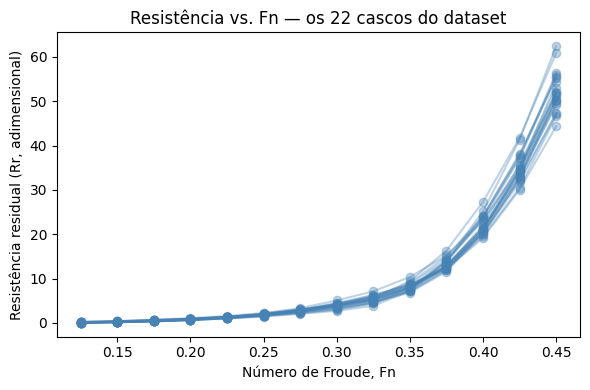

In [4]:
fig, ax = plt.subplots(figsize=(6,4))
for _, geom in df.groupby(["LCB", "Cp", "L_disp", "B_T", "L_B"]):
    geom = geom.sort_values("Froude")
    ax.plot(geom["Froude"], geom["Rr"], marker="o", alpha=0.35, color="steelblue")
ax.set_xlabel("Número de Froude, Fn")
ax.set_ylabel("Resistência residual (Rr, adimensional)")
ax.set_title("Resistência vs. Fn — os 22 cascos do dataset")
plt.tight_layout()
plt.show()


## 3. Preparar os dados para treino

- Split treino/teste
- Padronização (média 0, desvio 1) das entradas e da saída — as escalas das colunas variam bastante
  (Fn ~ 0.1-0.5, Rr ~ 0-60).


In [5]:
feature_cols = ["LCB", "Cp", "L_disp", "B_T", "L_B", "Froude"]
design_cols = ["LCB", "Cp", "L_disp", "B_T", "L_B"]  # sem o Froude -- é o espaço de projeto da Seção 9
target_col = "Rr"

X = df[feature_cols].values.astype(np.float32)
y = df[target_col].values.astype(np.float32).reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

x_scaler = StandardScaler().fit(X_train)
y_scaler = StandardScaler().fit(y_train)

X_train_s = x_scaler.transform(X_train).astype(np.float32)
X_test_s = x_scaler.transform(X_test).astype(np.float32)
y_train_s = y_scaler.transform(y_train).astype(np.float32)
y_test_s = y_scaler.transform(y_test).astype(np.float32)

X_train_t = torch.from_numpy(X_train_s)
y_train_t = torch.from_numpy(y_train_s)
X_test_t = torch.from_numpy(X_test_s)
y_test_t = torch.from_numpy(y_test_s)

print("treino:", X_train_t.shape, " teste:", X_test_t.shape)


treino: torch.Size([246, 6])  teste: torch.Size([62, 6])


## 4. Surrogate 1 — MLP (PyTorch)

Arquitetura pequena de propósito: 6 entradas → 2 camadas ocultas (32, 32) com ativação `tanh` → 1 saída.


In [6]:
class SurrogateMLP(nn.Module):
    def __init__(self, n_in=6, n_hidden=32, n_out=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, n_hidden), nn.Tanh(),
            nn.Linear(n_hidden, n_hidden), nn.Tanh(),
            nn.Linear(n_hidden, n_out),
        )

    def forward(self, x):
        return self.net(x)

model = SurrogateMLP()
print(model)
print("Número de parâmetros:", sum(p.numel() for p in model.parameters()))


SurrogateMLP(
  (net): Sequential(
    (0): Linear(in_features=6, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): Tanh()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
Número de parâmetros: 1313


## 5. Treinar a MLP

Adam + MSE, poucas centenas de épocas (roda em segundos em CPU).

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
loss_fn = nn.MSELoss()

n_epochs = 800
history = []
for epoch in range(n_epochs):
    model.train()
    optimizer.zero_grad()
    pred = model(X_train_t)
    loss = loss_fn(pred, y_train_t)
    loss.backward()
    optimizer.step()
    history.append(loss.item())
    if epoch % 200 == 0 or epoch == n_epochs - 1:
        with torch.no_grad():
            test_loss = loss_fn(model(X_test_t), y_test_t).item()
        print(f"epoch {epoch:4d} | train MSE (padronizado) = {loss.item():.4f} | test MSE = {test_loss:.4f}")


epoch    0 | train MSE (padronizado) = 0.9777 | test MSE = 0.4269
epoch  200 | train MSE (padronizado) = 0.0006 | test MSE = 0.0008


epoch  400 | train MSE (padronizado) = 0.0003 | test MSE = 0.0006
epoch  600 | train MSE (padronizado) = 0.0002 | test MSE = 0.0005


epoch  799 | train MSE (padronizado) = 0.0002 | test MSE = 0.0005


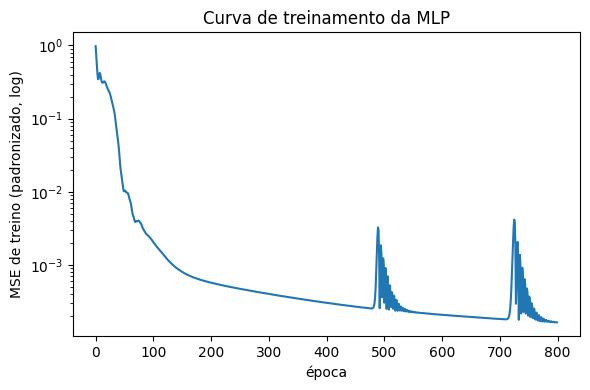

In [8]:
plt.figure(figsize=(6,4))
plt.plot(history)
plt.yscale("log")
plt.xlabel("época")
plt.ylabel("MSE de treino (padronizado, log)")
plt.title("Curva de treinamento da MLP")
plt.tight_layout()
plt.show()


## 6. Surrogate 2 — interpolador RBF (SciPy)

Antes do deep learning, esta é a família clássica de surrogate em otimização de projeto (junto com Kriging):
uma soma ponderada de funções de base radial centradas nos próprios pontos de treino. Treinamos sobre os
**mesmos** dados padronizados (mesmo split, mesmo `x_scaler`/`y_scaler`) para comparação justa com a MLP.


In [9]:
rbf_model = RBFInterpolator(
    X_train_s, y_train_s.flatten(),
    kernel="thin_plate_spline", smoothing=1e-2,
)

pred_test_rbf_s = rbf_model(X_test_s)
pred_test_rbf = pred_test_rbf_s * y_scaler.scale_[0] + y_scaler.mean_[0]
true_test_rbf = y_scaler.inverse_transform(y_test_s).flatten()

r2_rbf = 1 - np.sum((true_test_rbf - pred_test_rbf) ** 2) / np.sum((true_test_rbf - true_test_rbf.mean()) ** 2)
mae_rbf = np.mean(np.abs(true_test_rbf - pred_test_rbf))
print(f"RBF  -> R² (teste) = {r2_rbf:.4f}   MAE (teste) = {mae_rbf:.3f}")


RBF  -> R² (teste) = 0.9967   MAE (teste) = 0.389


## 7. Avaliar: predicted vs. measured (MLP e RBF lado a lado)

MLP  -> R² (teste) = 0.9992   MAE (teste) = 0.258
RBF  -> R² (teste) = 0.9967   MAE (teste) = 0.389


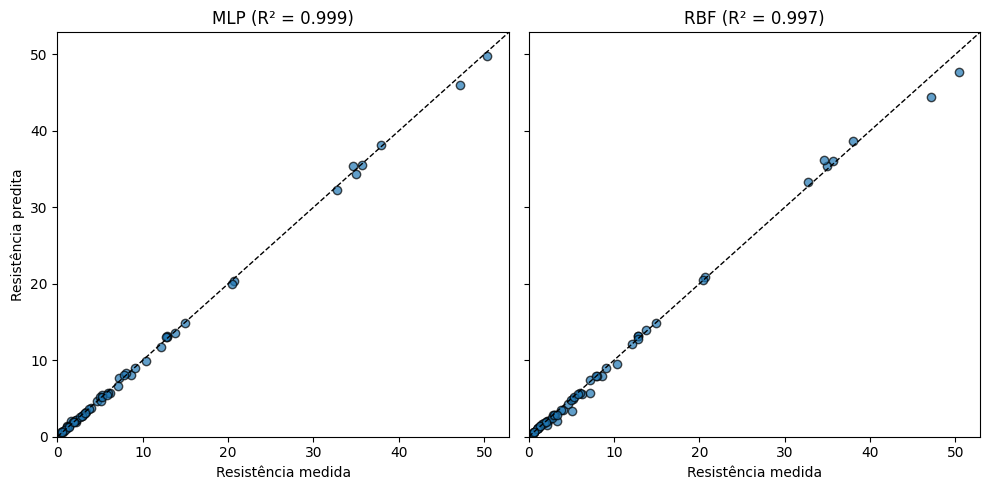

In [10]:
model.eval()
with torch.no_grad():
    pred_test_mlp_s = model(X_test_t).numpy()
pred_test_mlp = y_scaler.inverse_transform(pred_test_mlp_s).flatten()
true_test = y_scaler.inverse_transform(y_test_s).flatten()

r2_mlp = 1 - np.sum((true_test - pred_test_mlp) ** 2) / np.sum((true_test - true_test.mean()) ** 2)
mae_mlp = np.mean(np.abs(true_test - pred_test_mlp))
print(f"MLP  -> R² (teste) = {r2_mlp:.4f}   MAE (teste) = {mae_mlp:.3f}")
print(f"RBF  -> R² (teste) = {r2_rbf:.4f}   MAE (teste) = {mae_rbf:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
lims = [0, max(true_test.max(), pred_test_mlp.max(), pred_test_rbf.max()) * 1.05]
for ax, pred, name, r2 in [(axes[0], pred_test_mlp, "MLP", r2_mlp), (axes[1], pred_test_rbf, "RBF", r2_rbf)]:
    ax.plot(lims, lims, "k--", lw=1)
    ax.scatter(true_test, pred, alpha=0.7, edgecolor="k")
    ax.set_xlabel("Resistência medida")
    ax.set_title(f"{name} (R² = {r2:.3f})")
    ax.set_xlim(lims); ax.set_ylim(lims)
axes[0].set_ylabel("Resistência predita")
plt.tight_layout()
plt.show()


## 8. A curva de resistência vs. Froude — os surrogates reproduzem a física?

Fixamos a geometria de um casco (valores médios do dataset) e variamos só o número de Froude, num grid mais
fino do que os 14 pontos originais.


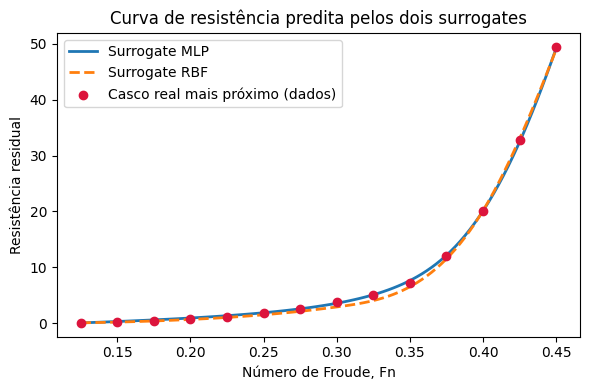

In [11]:
base_geom = df[design_cols].mean().values

fn_grid = np.linspace(0.125, 0.450, 100)
X_grid = np.column_stack([np.tile(base_geom, (len(fn_grid), 1)), fn_grid]).astype(np.float32)
X_grid_s = x_scaler.transform(X_grid).astype(np.float32)

with torch.no_grad():
    pred_grid_mlp = y_scaler.inverse_transform(model(torch.from_numpy(X_grid_s)).numpy()).flatten()
pred_grid_rbf = rbf_model(X_grid_s) * y_scaler.scale_[0] + y_scaler.mean_[0]

plt.figure(figsize=(6,4))
plt.plot(fn_grid, pred_grid_mlp, lw=2, label="Surrogate MLP")
plt.plot(fn_grid, pred_grid_rbf, lw=2, ls="--", label="Surrogate RBF")

dists = np.linalg.norm(df[design_cols].values - base_geom, axis=1)
geom_ref = df.loc[df.iloc[[dists.argmin()]].index[0], design_cols]
mask = (df[design_cols] - geom_ref).abs().sum(axis=1) < 1e-6
real_points = df[mask].sort_values("Froude")
plt.scatter(real_points["Froude"], real_points["Rr"], color="crimson", zorder=5, label="Casco real mais próximo (dados)")

plt.xlabel("Número de Froude, Fn")
plt.ylabel("Resistência residual")
plt.title("Curva de resistência predita pelos dois surrogates")
plt.legend()
plt.tight_layout()
plt.show()


## 9. Conectando com otimização — respeitando o domínio de treino

Com um surrogate treinado, uma avaliação de `(geometria, Fn) → resistência` custa microssegundos. Isso torna
viável usar o surrogate como função-objetivo de um problema de otimização de projeto — mas só se tomarmos
cuidado com **onde** deixamos o otimizador procurar.

**O problema com limites por variável:** restringir cada uma das 5 variáveis geométricas ao seu próprio
`[min, max]` observado *não garante* que uma combinação das 5 esteja dentro da região realmente coberta
pelos dados — o dataset tem só **22 combinações reais**, não um grid contínuo. Um otimizador de gradiente
pode encontrar uma combinação individualmente dentro dos limites, mas nunca vista em conjunto: extrapolação
disfarçada de interpolação.

**A correção:** restringir todo candidato a ser uma **combinação convexa dos 22 cascos reais**
$\big(\mathbf{x} = \sum_i w_i\, \mathbf{h}_i,\ w_i \ge 0,\ \sum_i w_i = 1\big)$. Geometricamente, isso
garante que o candidato fica sempre dentro do fecho convexo dos dados observados — sempre em regime de
interpolação, nunca de extrapolação. É a mesma ideia usada no notebook de otimização Bayesiana do curso.

Como a combinação convexa é **linear** em $w$, ainda dá para otimizar com gradiente exato via autograd
(para a MLP) ou via diferenças finitas (para o RBF) — SQP (`SLSQP`) trata $w$ no simplex naturalmente:
bounds $w_i \in [0,1]$ + uma restrição de igualdade $\sum_i w_i = 1$.


In [12]:
# --- 9.1 Baseline: melhor entre as 22 geometrias REALMENTE testadas ---
unique_hulls = df[design_cols].drop_duplicates().values
n_hulls = unique_hulls.shape[0]
fn_design_t = torch.tensor(fn_grid, dtype=torch.float32).reshape(-1, 1)

def mean_resistance_mlp(geom_np):
    Xg = np.column_stack([np.tile(geom_np, (len(fn_grid), 1)), fn_grid]).astype(np.float32)
    Xg_s = x_scaler.transform(Xg).astype(np.float32)
    with torch.no_grad():
        pg_s = model(torch.from_numpy(Xg_s)).numpy()
    return y_scaler.inverse_transform(pg_s).mean()

def mean_resistance_rbf(geom_np):
    Xg = np.column_stack([np.tile(geom_np, (len(fn_grid), 1)), fn_grid]).astype(np.float32)
    Xg_s = x_scaler.transform(Xg).astype(np.float32)
    pg_s = rbf_model(Xg_s)
    return (pg_s * y_scaler.scale_[0] + y_scaler.mean_[0]).mean()

best_geom_baseline, best_mean_r_baseline = None, np.inf
for g in unique_hulls:
    r = mean_resistance_mlp(g)
    if r < best_mean_r_baseline:
        best_mean_r_baseline, best_geom_baseline = r, g

print("Número de cascos (formas) distintos no dataset:", n_hulls)
print("[baseline, MLP] menor resistência média entre geometrias JÁ TESTADAS:", round(best_mean_r_baseline, 3))
print("[baseline, MLP] geometria correspondente:", np.round(best_geom_baseline, 3))


Número de cascos (formas) distintos no dataset: 22
[baseline, MLP] menor resistência média entre geometrias JÁ TESTADAS: 8.361
[baseline, MLP] geometria correspondente: [-2.4    0.585  4.78   3.84   3.32 ]


In [13]:
# --- 9.2 Otimização com a MLP, restrita ao fecho convexo dos 22 cascos reais ---
unique_hulls_t = torch.tensor(unique_hulls, dtype=torch.float32)  # (22, 5)
x_mean_t = torch.tensor(x_scaler.mean_, dtype=torch.float32)
x_std_t = torch.tensor(x_scaler.scale_, dtype=torch.float32)
y_mean_t = torch.tensor(y_scaler.mean_, dtype=torch.float32)
y_std_t = torch.tensor(y_scaler.scale_, dtype=torch.float32)

def mlp_mean_resistance_and_grad(w_np):
    """w_np: pesos (22,) no simplex. Retorna resistência média (sobre a faixa de Fn) e seu
    gradiente exato em relação a w, via autograd -- a combinação convexa é linear, então o
    grafo de diferenciação passa direto da MLP para os pesos."""
    w = torch.tensor(w_np, dtype=torch.float32, requires_grad=True)
    design = w @ unique_hulls_t                                   # (5,) -- combinação convexa
    x_full = torch.cat([design.unsqueeze(0).repeat(len(fn_design_t), 1), fn_design_t], dim=1)
    x_full_s = (x_full - x_mean_t) / x_std_t
    pred = model(x_full_s) * y_std_t + y_mean_t
    obj = pred.mean()
    grad_w, = torch.autograd.grad(obj, w)
    return obj.item(), grad_w.numpy().astype(np.float64)

bounds_w = [(0.0, 1.0)] * n_hulls
constraints_w = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones_like(w)}]

rng = np.random.default_rng(0)
best_mlp_opt = None
for trial in range(6):
    w0 = rng.dirichlet(np.ones(n_hulls))
    res = opt.minimize(
        fun=lambda w: mlp_mean_resistance_and_grad(w)[0],
        x0=w0,
        jac=lambda w: mlp_mean_resistance_and_grad(w)[1],
        method="SLSQP", bounds=bounds_w, constraints=constraints_w,
        options={"maxiter": 200, "ftol": 1e-9},
    )
    if res.success and (best_mlp_opt is None or res.fun < best_mlp_opt.fun):
        best_mlp_opt = res

geom_opt_mlp = best_mlp_opt.x @ unique_hulls
print("[SQP, surrogate MLP] resistência média prevista no ótimo:", round(best_mlp_opt.fun, 3))
print("[SQP, surrogate MLP] geometria ótima (combinação convexa):", np.round(geom_opt_mlp, 3))
print(f"[SQP, surrogate MLP] redução vs. baseline: {100*(1 - best_mlp_opt.fun/best_mean_r_baseline):.1f}%")
print("(por construção, geom_opt_mlp está sempre dentro do fecho convexo dos 22 cascos reais)")


[SQP, surrogate MLP] resistência média prevista no ótimo: 8.183
[SQP, surrogate MLP] geometria ótima (combinação convexa): [-2.422  0.582  4.672  3.546  3.331]
[SQP, surrogate MLP] redução vs. baseline: 2.1%
(por construção, geom_opt_mlp está sempre dentro do fecho convexo dos 22 cascos reais)


In [14]:
# --- 9.3 A MESMA otimização, agora usando o surrogate RBF (gradiente via diferenças finitas) ---
def rbf_mean_resistance(w_np):
    geom = w_np @ unique_hulls
    return mean_resistance_rbf(geom)

best_rbf_opt = None
for trial in range(6):
    w0 = rng.dirichlet(np.ones(n_hulls))
    res = opt.minimize(
        fun=rbf_mean_resistance,
        x0=w0,
        method="SLSQP", bounds=bounds_w, constraints=constraints_w,
        options={"maxiter": 200, "ftol": 1e-9},
    )
    if res.success and (best_rbf_opt is None or res.fun < best_rbf_opt.fun):
        best_rbf_opt = res

geom_opt_rbf = best_rbf_opt.x @ unique_hulls
print("[SQP, surrogate RBF] resistência média prevista no ótimo:", round(best_rbf_opt.fun, 3))
print("[SQP, surrogate RBF] geometria ótima (combinação convexa):", np.round(geom_opt_rbf, 3))
print(f"[SQP, surrogate RBF] redução vs. baseline: {100*(1 - best_rbf_opt.fun/best_mean_r_baseline):.1f}%")


[SQP, surrogate RBF] resistência média prevista no ótimo: 8.083
[SQP, surrogate RBF] geometria ótima (combinação convexa): [-2.276  0.563  4.83   3.8    3.307]
[SQP, surrogate RBF] redução vs. baseline: 3.3%


## 10. MLP vs. RBF concordam sobre qual é o casco ótimo?

Cada surrogate encontrou seu próprio "melhor" design. A pergunta que importa em projeto real: será que um
surrogate concorda com a avaliação do outro? Cruzamos as duas geometrias ótimas pelos dois surrogates —
se os quatro números forem parecidos, os modelos concordam; se não, é sinal de que a escolha do surrogate
importa tanto quanto a escolha do otimizador.


In [15]:
cross_table = pd.DataFrame(
    {
        "avaliado pelo MLP": [mean_resistance_mlp(geom_opt_mlp), mean_resistance_mlp(geom_opt_rbf)],
        "avaliado pelo RBF": [mean_resistance_rbf(geom_opt_mlp), mean_resistance_rbf(geom_opt_rbf)],
    },
    index=["ótimo encontrado pelo MLP", "ótimo encontrado pelo RBF"],
)
cross_table.round(3)


,avaliado pelo MLP,avaliado pelo RBF
ótimo encontrado pelo MLP,8.183,8.401
ótimo encontrado pelo RBF,8.716,8.083


---
**Para a aula:** vale terminar aqui reforçando o fluxo fechado — *dado → surrogate → predição rápida →
otimização de projeto respeitando o domínio dos dados* — e a mensagem final: a escolha da **família do
surrogate** (MLP vs. RBF vs. Kriging/GP) é, ela mesma, uma decisão de projeto, não um detalhe técnico —
diferentes surrogates podem levar a diferentes designs "ótimos" mesmo partindo dos mesmos dados. É a ponte
natural para a Aula 2, onde o surrogate deixará de ser puramente data-driven e passará a incorporar a
física da EDP diretamente na função de perda.
